# 01 — Dados e Tipos de Variáveis

Bem-vindo ao **ML-00**, o livro de **nivelamento** da série. Os livros [ML-01 (regressão)](https://github.com/JoaoBLeite/ML-01-Introducao-regressao) e [ML-02 (classificação)](https://github.com/JoaoBLeite/ML-02-Introducao-classificacao) usam o tempo todo palavras como *média*, *desvio padrão*, *correlação*, *probabilidade*, *distribuição*, *intervalo* e *verossimilhança*. Aqui vamos construir cada uma delas do zero, com Python.

Por que estatística e probabilidade antes do Machine Learning?
- **Estatística** é a arte de **resumir e aprender com dados**. Todo projeto de ML começa olhando os dados (a análise exploratória) e termina medindo erros (métricas), e as duas coisas são estatística.
- **Probabilidade** é a linguagem da **incerteza**. Um modelo nunca tem certeza: ele diz "70% de chance de renda alta" ou "a casa vale US\$ 200 mil, mais ou menos US\$ 30 mil".

Neste primeiro notebook vamos:
- Entender a diferença entre **população** e **amostra**
- Conhecer os **tipos de variáveis** (numéricas e categóricas)
- Dar os primeiros passos com **numpy** e **pandas**
- Contar **frequências** e encontrar **valores ausentes**

## 1. Importando bibliotecas

In [1]:
# "import X as Y" carrega uma biblioteca e dá a ela um apelido curto, que usaremos no resto do notebook.
import numpy as np               # numpy: contas rápidas com vetores e matrizes de números
import pandas as pd              # pandas: tabelas (DataFrames), como uma planilha dentro do Python
import matplotlib.pyplot as plt  # matplotlib: gráficos
import seaborn as sns            # seaborn: gráficos estatísticos prontos e alguns datasets de exemplo

# Configurações de exibição: 3 casas decimais nas tabelas e gráficos um pouco maiores.
pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 100

## 2. O nosso primeiro dataset: gorjetas

O dataset **tips** (gorjetas) foi coletado por um garçom num restaurante dos EUA nos anos 1990. Cada linha é **uma mesa atendida**, com o valor da conta, a gorjeta e algumas informações sobre a mesa. Ele é pequeno (244 linhas), o que facilita enxergar tudo o que acontece.

> 🌐 `sns.load_dataset` baixa o dataset da internet na primeira vez e guarda uma cópia no seu computador.

In [2]:
# load_dataset devolve um DataFrame do pandas: uma tabela com linhas e colunas nomeadas.
gorjetas = sns.load_dataset("tips")

# .shape é uma tupla (linhas, colunas). O f-string (f"...") insere valores do Python dentro do texto com {}.
print(f"O dataset tem {gorjetas.shape[0]} linhas e {gorjetas.shape[1]} colunas")

# .head() mostra as 5 primeiras linhas.
gorjetas.head()

O dataset tem 244 linhas e 7 colunas


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


O que significa cada coluna:

| Coluna | Significado |
|---|---|
| `total_bill` | valor total da conta (US\$) |
| `tip` | gorjeta (US\$) |
| `sex` | sexo de quem pagou |
| `smoker` | se havia fumantes na mesa |
| `day` | dia da semana |
| `time` | refeição: almoço (*Lunch*) ou jantar (*Dinner*) |
| `size` | número de pessoas na mesa |

## 🎓 Conceito: população e amostra

- **População** é o conjunto **inteiro** sobre o qual queremos tirar conclusões: *todas* as mesas que esse restaurante já atendeu (e ainda vai atender).
- **Amostra** é a parte que **de fato observamos**: as 244 mesas que o garçom anotou.

Analogia: para saber se a sopa está salgada, você não bebe a panela inteira (a população). Você prova **uma colher** (a amostra). Se a sopa estiver bem mexida, uma colher basta para tirar uma boa conclusão.

Quase sempre só temos uma amostra. Por isso, os números que calculamos (a média das gorjetas, por exemplo) são **estimativas** do número verdadeiro da população, e mudariam um pouco se tivéssemos outra amostra. Medir **quanto** eles mudariam é o assunto da Parte III deste livro (inferência).

🔗 **Ponte para o ML:** o dataset de treino de um modelo é uma **amostra**. O que queremos é que o modelo funcione bem na **população** (dados novos que ele nunca viu). É por isso que, no ML-01 e no ML-02, separamos um **conjunto de teste**: ele faz o papel de "uma nova colher de sopa".

## 3. Simulando: a amostra muda, a população não

Não conhecemos a população verdadeira das gorjetas. Mas podemos **inventar** uma população com o computador e ver o que acontece quando tiramos amostras dela. Essa ideia, **simular para entender**, vai aparecer em todo o livro.

In [3]:
# default_rng cria um gerador de números aleatórios. A semente (42) faz os "sorteios" serem sempre os mesmos,
# para que os números deste notebook se repitam toda vez que você rodá-lo.
rng = np.random.default_rng(42)

# Uma "população" inventada: o valor da conta de 100.000 mesas.
# rng.gamma sorteia números positivos e assimétricos, parecidos com valores de contas (detalhes no notebook 08).
populacao = rng.gamma(shape=4, scale=5, size=100_000)   # o _ em 100_000 só facilita a leitura do número

print(f"Média da POPULAÇÃO: US$ {populacao.mean():.2f}")   # :.2f formata com 2 casas decimais

# Agora "anotamos" 5 amostras diferentes de 244 mesas cada (o tamanho do dataset tips).
for i in range(5):   # range(5) gera 0, 1, 2, 3, 4
    # rng.choice sorteia 244 elementos da população, sem repetir a mesma mesa (replace=False).
    amostra = rng.choice(populacao, size=244, replace=False)
    print(f"  Amostra {i + 1}: média US$ {amostra.mean():.2f}")

Média da POPULAÇÃO: US$ 20.01
  Amostra 1: média US$ 19.97
  Amostra 2: média US$ 19.75
  Amostra 3: média US$ 20.09
  Amostra 4: média US$ 19.13
  Amostra 5: média US$ 21.04


**Conclusão:** a média da população inventada é **US\$ 20,01**, mas cada amostra de 244 mesas dá um número diferente: 19,97, 19,75, 20,09, **19,13** e **21,04**. Nenhuma acerta em cheio, mas todas ficam perto, a no máximo ~US\$ 1 de distância.

É exatamente a situação do garçom: a média das 244 mesas que ele anotou é **uma** dessas estimativas. Se ele tivesse anotado outras 244 mesas, o número seria um pouco diferente. Guarde esta ideia: um número calculado numa amostra sempre vem com uma **incerteza**, e boa parte deste livro é sobre como medi-la.

## 🎓 Conceito: tipos de variáveis

Cada coluna de um dataset é uma **variável**. O tipo da variável decide **quais contas e gráficos fazem sentido**:

| Tipo | Subtipo | O que é | Exemplo no `tips` |
|---|---|---|---|
| **Numérica** (quantitativa) | **contínua** | pode assumir qualquer valor num intervalo | `total_bill`, `tip` |
| | **discreta** | só valores "contáveis" (0, 1, 2, ...) | `size` |
| **Categórica** (qualitativa) | **nominal** | categorias **sem ordem** | `sex`, `smoker`, `time` |
| | **ordinal** | categorias **com ordem** natural | `day` (quinta → domingo) |

Analogia: numa ficha de cadastro, "altura" é **contínua** (1,73 m), "número de filhos" é **discreta** (2), "cor favorita" é **nominal** (não existe "azul > verde") e "escolaridade" é **ordinal** (fundamental < médio < superior).

Por que isso importa? Faz sentido calcular a **média** de `total_bill`, mas não a "média" de `sex`. Para categóricas, contamos **frequências**.

🔗 **Ponte para o ML:** no ML-02, as colunas categóricas do Adult Income precisaram de um tratamento especial (o **one-hot encoding**), justamente porque um modelo só sabe fazer contas com números.

In [4]:
# .dtypes mostra o tipo que o pandas usa para guardar cada coluna.
# float64 = número com casas decimais; int64 = número inteiro; category = categoria.
gorjetas.dtypes

total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object

In [5]:
# .select_dtypes separa as colunas pelo tipo. .columns devolve os nomes e list() os transforma numa lista do Python.
colunas_numericas = list(gorjetas.select_dtypes(include="number").columns)
colunas_categoricas = list(gorjetas.select_dtypes(include="category").columns)
print("Numéricas:  ", colunas_numericas)
print("Categóricas:", colunas_categoricas)

# Uma coluna categórica do pandas guarda as categorias possíveis. Em "day", elas já vêm na ordem da semana:
print("\nCategorias de 'day':", list(gorjetas["day"].cat.categories))

Numéricas:   ['total_bill', 'tip', 'size']
Categóricas: ['sex', 'smoker', 'day', 'time']

Categorias de 'day': ['Thur', 'Fri', 'Sat', 'Sun']


**Conclusão:** o pandas já reconhece os tipos: `total_bill` e `tip` são `float64` (contínuas), `size` é `int64` (discreta) e as outras quatro são `category`. Repare que a categoria `day` guarda a **ordem** da semana (`Thur`, `Fri`, `Sat`, `Sun`), o que a torna uma variável **ordinal**; já `sex`, `smoker` e `time` são **nominais**.

Atenção: o tipo que o computador usa nem sempre é o tipo estatístico. `size` é guardada como número inteiro e de fato é discreta, mas uma coluna como "CEP" também seria guardada como número, e calcular a "média dos CEPs" não faz sentido nenhum. Quem decide o tipo estatístico é **o significado** da variável.

## 4. Primeiros passos com numpy

Uma coluna do pandas é, por dentro, um **vetor do numpy** (`ndarray`). O numpy faz contas com o vetor **inteiro de uma vez**, sem precisar de laços `for`. Isso se chama **vetorização** e é muito mais rápido e legível.

In [6]:
# .to_numpy() extrai a coluna como um vetor do numpy.
contas = gorjetas["total_bill"].to_numpy()
gorjetas_valor = gorjetas["tip"].to_numpy()

print("Tipo do objeto:", type(contas))
print("Primeiros 5 valores:", contas[:5])   # [:5] = "do começo até a posição 5 (exclusive)"

# Vetorização: a divisão é feita elemento a elemento, para as 244 mesas de uma vez.
percentual = gorjetas_valor / contas * 100
print("Percentual de gorjeta das 5 primeiras mesas:", np.round(percentual[:5], 1))

# Funções de resumo do numpy:
print(f"\nSoma das contas:  US$ {contas.sum():.2f}")
print(f"Menor conta:      US$ {contas.min():.2f}")
print(f"Maior conta:      US$ {contas.max():.2f}")
print(f"Gorjeta média:    {percentual.mean():.1f}% da conta")

Tipo do objeto: <class 'numpy.ndarray'>
Primeiros 5 valores: [16.99 10.34 21.01 23.68 24.59]
Percentual de gorjeta das 5 primeiras mesas: [ 5.9 16.1 16.7 14.  14.7]

Soma das contas:  US$ 4827.77
Menor conta:      US$ 3.07
Maior conta:      US$ 50.81
Gorjeta média:    16.1% da conta


In [7]:
# Guardamos o percentual como uma nova coluna do DataFrame: basta atribuir a um nome novo entre colchetes.
gorjetas["percentual"] = gorjetas["tip"] / gorjetas["total_bill"] * 100

# Filtros: uma comparação gera um vetor de True/False (uma "máscara"), que seleciona as linhas.
mascara = gorjetas["percentual"] > 25
print(f"Mesas com gorjeta acima de 25%: {mascara.sum()}")   # True conta como 1, então .sum() conta os True
gorjetas[mascara]

Mesas com gorjeta acima de 25%: 10


,total_bill,tip,sex,smoker,day,time,size,percentual
51,10.29,2.60,Female,No,Sun,Dinner,2,25.267
67,3.07,1.00,Female,Yes,Sat,Dinner,1,32.573
93,16.32,4.30,Female,Yes,Fri,Dinner,2,26.348
109,14.31,4.00,Female,Yes,Sat,Dinner,2,27.952
149,7.51,2.00,Male,No,Thur,Lunch,2,26.631
172,7.25,5.15,Male,Yes,Sun,Dinner,2,71.034
178,9.60,4.00,Female,Yes,Sun,Dinner,2,41.667
183,23.17,6.50,Male,Yes,Sun,Dinner,4,28.054
221,13.42,3.48,Female,Yes,Fri,Lunch,2,25.931
232,11.61,3.39,Male,No,Sat,Dinner,2,29.199


**Conclusão:** a gorjeta média é **16,1%** da conta, com contas entre **US\$ 3,07** e **US\$ 50,81**. A primeira mesa deu só 5,9% de gorjeta, enquanto a maioria das outras fica perto de 15%.

Só **10** das 244 mesas deram mais de 25% de gorjeta, e uma delas chama atenção: a mesa 172, com conta de US\$ 7,25 e gorjeta de US\$ 5,15, ou seja, **71%** da conta. Um valor tão diferente dos outros é um **outlier**, e o notebook 02 vai mostrar como ele pode distorcer a média.

## 🎓 Conceito: frequência absoluta e relativa

Para uma variável **categórica**, o resumo natural é contar quantas vezes cada categoria aparece:
- **Frequência absoluta:** a contagem (por exemplo, 87 mesas no sábado).
- **Frequência relativa:** a proporção do total (87 / 244 = 35,7%).

A frequência relativa é a primeira aparição da **probabilidade** neste livro: se sorteássemos uma mesa ao acaso, a chance de ela ser de sábado seria 35,7%.

In [8]:
# value_counts conta cada categoria. sort=False mantém a ordem das categorias (quinta, sexta, sábado, domingo).
absoluta = gorjetas["day"].value_counts(sort=False)
# normalize=True divide pelo total, dando a frequência relativa.
relativa = gorjetas["day"].value_counts(sort=False, normalize=True)

# pd.DataFrame com um dicionário {nome_da_coluna: dados} monta uma tabela lado a lado.
tabela_dias = pd.DataFrame({"mesas": absoluta, "proporção": relativa})
tabela_dias

,mesas,proporção
day,,
Thur,62,0.254
Fri,19,0.078
Sat,87,0.357
Sun,76,0.311


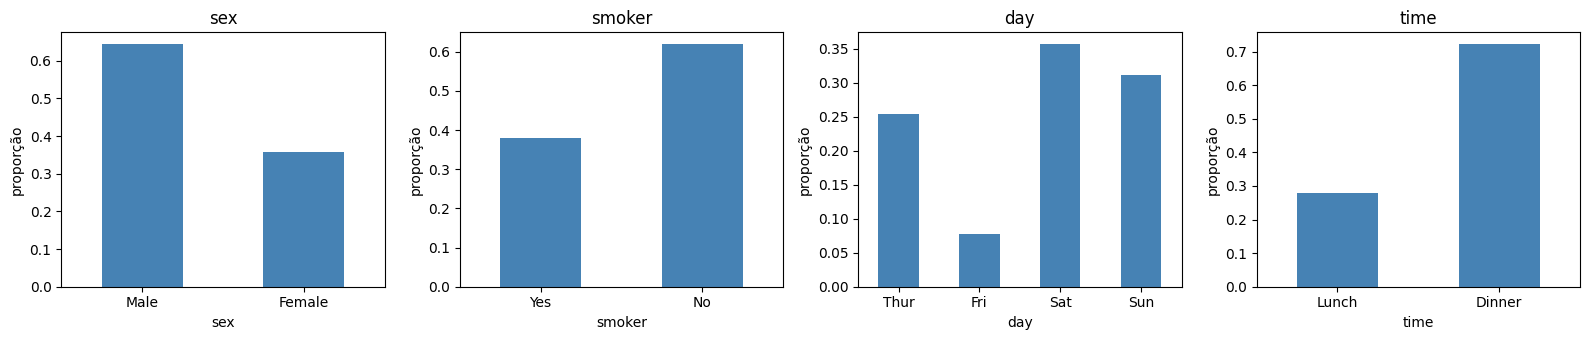

In [9]:
# Gráfico de barras das frequências, para as 4 colunas categóricas.
# plt.subplots(1, 4) cria uma figura com 4 gráficos lado a lado; "axes" é a lista desses gráficos.
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
# zip junta duas listas em pares: (coluna_1, eixo_1), (coluna_2, eixo_2)...
for coluna, ax in zip(colunas_categoricas, axes):
    gorjetas[coluna].value_counts(sort=False, normalize=True).plot.bar(ax=ax, color="steelblue")
    ax.set_title(coluna)
    ax.set_ylabel("proporção")
    ax.tick_params(axis="x", rotation=0)   # deixa os rótulos do eixo x na horizontal
plt.tight_layout()
plt.show()

**Conclusão:** - **Dia:** o sábado concentra **35,7%** das mesas (87), seguido do domingo (31,1%) e da quinta (25,4%). A sexta tem só **19 mesas (7,8%)**; qualquer conclusão sobre a sexta vai se apoiar em pouquíssimos dados.
- **Refeição:** cerca de 72% das mesas são de jantar.
- **Sexo e fumantes:** cerca de 64% das contas foram pagas por homens, e em cerca de 62% das mesas não havia fumantes.

Categorias com poucos exemplos, como a sexta-feira, são uma preocupação recorrente: no ML-02, categorias raras do Adult Income foram agrupadas justamente por isso.

## 🎓 Conceito: tabela de frequências para uma variável numérica

Uma variável **discreta** com poucos valores, como `size`, também pode ser resumida por frequências. Já uma variável **contínua**, como `total_bill`, quase nunca repete valores, então primeiro agrupamos os valores em **faixas** (intervalos) e contamos quantos caem em cada faixa. Essa é a ideia do **histograma**, que veremos com calma no notebook 03.

In [10]:
# Variável discreta: contar diretamente. sort_index() ordena pelo valor (1, 2, 3...) em vez de pela contagem.
print("Pessoas por mesa:")
print(gorjetas["size"].value_counts().sort_index())

# Variável contínua: pd.cut corta os valores em faixas. bins = os limites das faixas.
faixas = pd.cut(gorjetas["total_bill"], bins=[0, 10, 20, 30, 40, 60])
print("\nValor da conta por faixa:")
print(faixas.value_counts(sort=False))

Pessoas por mesa:
size
1      4
2    156
3     38
4     37
5      5
6      4
Name: count, dtype: int64

Valor da conta por faixa:
total_bill
(0, 10]      17
(10, 20]    130
(20, 30]     65
(30, 40]     22
(40, 60]     10
Name: count, dtype: int64


**Conclusão:** - **Pessoas por mesa:** a grande maioria é de mesas de **2 pessoas (156 de 244)**. Mesas de 1, 5 e 6 pessoas são raras (4, 5 e 4).
- **Valor da conta:** a faixa de US\$ 10 a US\$ 20 tem **130 mesas**, mais da metade. Depois as contagens vão caindo: 65 entre 20 e 30, 22 entre 30 e 40 e só 10 acima de 40. Os valores se concentram à esquerda e têm uma "cauda" longa para a direita, um formato chamado **assimétrico**, que vamos explorar no notebook 03.

## 5. Valores ausentes

Dados reais quase sempre têm **buracos**: informações que não foram anotadas. O `tips` é um dataset "limpo", então vamos olhar outro: o **penguins**, com medidas de 344 pinguins de três espécies da Antártida. Ele será o nosso segundo dataset ao longo do livro.

In [11]:
pinguins = sns.load_dataset("penguins")
print(f"O dataset tem {pinguins.shape[0]} linhas e {pinguins.shape[1]} colunas")

# .isna() marca True onde falta valor; .sum() conta os True de cada coluna.
ausentes = pd.DataFrame({
    "ausentes": pinguins.isna().sum(),
    "proporção": pinguins.isna().mean(),   # média de True/False = proporção de True
})
ausentes

O dataset tem 344 linhas e 7 colunas


,ausentes,proporção
species,0,0.000
island,0,0.000
bill_length_mm,2,0.006
bill_depth_mm,2,0.006
flipper_length_mm,2,0.006
body_mass_g,2,0.006
sex,11,0.032


In [12]:
# Quais linhas têm algum valor ausente? .any(axis=1) pergunta "há algum True nesta LINHA?".
pinguins[pinguins.isna().any(axis=1)]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


**Conclusão:** no penguins, faltam as medidas do corpo de **2 pinguins** (0,6%) e o sexo de **11** (3,2%). As duas linhas sem medidas (3 e 339) não têm **nenhuma** informação além da espécie e da ilha; as outras 9 só não têm o sexo.

São poucos buracos, mas eles já obrigam a uma decisão: descartar essas linhas ou preencher os valores? Nos próximos notebooks, quando precisarmos das medidas, vamos simplesmente descartar as linhas incompletas (com `.dropna()`). No ML-01 e no ML-02, o preenchimento foi feito com o `SimpleImputer`, dentro de um pipeline.

## 6. Um resumo rápido com `describe`

O método `.describe()` calcula, de uma vez, vários números de resumo para cada coluna numérica. Talvez você já o tenha visto no ML-01 e no ML-02. Cada linha dessa tabela (média, desvio padrão, quartis...) é o assunto do **próximo notebook**, onde vamos entender o que cada uma significa e quando usá-la.

In [13]:
gorjetas.describe()

,total_bill,tip,size,percentual
count,244.000,244.000,244.000,244.000
mean,19.786,2.998,2.570,16.080
std,8.902,1.384,0.951,6.107
min,3.070,1.000,1.000,3.564
25%,13.348,2.000,2.000,12.913
50%,17.795,2.900,2.000,15.477
75%,24.127,3.562,3.000,19.148
max,50.810,10.000,6.000,71.034


In [14]:
# Para colunas categóricas, describe mostra: quantos valores, quantas categorias, a mais frequente (top) e quantas vezes ela aparece (freq).
gorjetas.describe(include="category")

,sex,smoker,day,time
count,244,244,244,244
unique,2,2,4,2
top,Male,No,Sat,Dinner
freq,157,151,87,176


**Conclusão:** o `describe` resume as 244 mesas: a conta média é **US\$ 19,79** e a gorjeta média, **US\$ 3,00**, com um percentual médio de **16,1%**. Dá para notar que, na conta, a média (19,79) é maior que a mediana (a linha `50%`, 17,80), e que o máximo (50,81) está bem longe do terceiro quartil (24,13). Esses são sinais da cauda para a direita que vimos na tabela de faixas.

Nas categóricas, a categoria mais frequente (`top`) de cada coluna é `Male` (157 mesas), `No` (151), `Sat` (87) e `Dinner` (176), os mesmos números dos gráficos de barras.

## 7. Resumo e próximos passos

**Conceitos que você aprendeu**
- **População × amostra:** quase sempre só vemos uma amostra, e os números calculados nela são **estimativas** que mudam de amostra para amostra.
- **Tipos de variáveis:** numéricas (contínuas e discretas) e categóricas (nominais e ordinais). O tipo decide quais contas fazem sentido.
- **Frequência absoluta e relativa**, a primeira aparição da probabilidade.
- **Faixas** para resumir variáveis contínuas.
- **Valores ausentes** e como encontrá-los.

**Python novo:** `import ... as ...`, `np.random.default_rng`, `rng.gamma`, `rng.choice`, `sns.load_dataset`, `.shape`, `.head()`, `.dtypes`, `.select_dtypes`, `.to_numpy()`, vetorização, máscaras de True/False, `.value_counts()`, `pd.cut`, `.isna()`, `.any(axis=1)`, `.describe()`, f-strings com `:.2f`, `for`, `range`, `zip`.

**Próximo notebook:** o `describe` despejou uma porção de números (média, desvio padrão, quartis). No notebook 02 vamos entender cada um deles: o que medem, como calculá-los à mão e por que a **média** pode enganar quando existem **outliers**.